# Task substitution in Qwen3.5-4B

**Hypothesis.** When a prompt looks like a familiar task but differs in one key detail, a language model often solves the familiar, easier task instead. The result looks like a hallucination, but it is actually a correct answer to a different question.

**Data.** Two public English benchmarks of *original vs. minimally modified* problems:

| dataset | items used | what changes | license |
|---|---|---|---|
| [`marcodsn/altered-riddles`](https://huggingface.co/datasets/marcodsn/altered-riddles) | 700 altered riddles from 189 well-known originals | constraint addition, meaning shift, context swap, bias probe | Apache-2.0 |
| [`qintongli/GSM-Plus`](https://huggingface.co/datasets/qintongli/GSM-Plus) (ACL 2024) | 150 GSM8K problems × 3 changes | a needed fact removed (no answer), the question reversed, the numbers changed | CC-BY-SA-4.0 |

Every item carries the answer to the modified problem (`gold`) and the answer to the original (`shortcut`). If wrong answers land on `shortcut` far more often than on anything else, the errors are **substitution**, not random fabrication.

**Conditions** for each modified item:

| condition | prompt |
|---|---|
| `canonical` | the original problem (does the model know the familiar version?) |
| `perturbed` | the modified problem, no warning |
| `nudge` | the modified problem plus a generic "read carefully" warning |
| `contrast` | the original and modified problems side by side; answer the modified one |

A large gain from `perturbed` to `nudge`/`contrast` means the model *could* solve the modified problem but took the shortcut by default.

**Grading.** An LLM judge (Qwen3.5-9B) labels each final answer:

- **correct:** matches the modified problem's answer
- **shortcut:** matches the original problem's answer
- **other:** any other answer
- **no answer:** none given

A rule-based grader runs alongside it as a cross-check: number matching for GSM-Plus, and the datasets' accepted-answer lists for riddles.

**Runtime.** The defaults are for an **A100** (or L4) with vLLM, running the full item set in both thinking modes. On a free T4, vLLM fails to start; the config cell says what to change.

**How to run.**

1. Set the runtime to **A100 GPU**. Leave `QUICK_TEST = True` and click **Run All**. This takes a few minutes and checks every step on 10 items per dataset.
2. If it finished without errors, **restart the session** so the GPU is empty.
3. Set `QUICK_TEST = False` and `RUN_SMOKE_TEST = False`, then click **Run All** again for the full run.

Results are saved to your Hugging Face Bucket after every chunk. After a disconnect, just run everything again (with `RUN_SMOKE_TEST = False`): finished work is skipped, and a model is only loaded if something is left to do.

In [1]:
print('test')

test


## 0 · Configuration

In [2]:
MODEL_ID = "Qwen/Qwen3.5-4B"
JUDGE_MODEL_ID = "Qwen/Qwen3.5-9B"   # grades the answers

# Step 1: run everything once with QUICK_TEST = True (10 items per dataset and mode, a few minutes).
# Step 2: set QUICK_TEST = False and RUN_SMOKE_TEST = False, then run everything again for the full set.
#         The quick-test answers are reused, so nothing is generated twice.
QUICK_TEST = False
RUN_SMOKE_TEST = True                # also set False when resuming after a disconnect

# DANGER: True deletes all earlier generations, judgments, results and figures, locally AND in the bucket.
# Set it True for one run to start clean, then set it back to False right away, or the next run
# (or a resume after a disconnect) deletes everything again. The evaluation items are always rebuilt.
RESET_RESULTS = True

# Hardware. These defaults are for an A100 (or L4) with vLLM. On a free T4, vLLM fails to start:
# use ENGINE = "hf", MAX_NEW_TOKENS = {"no_think": 2048, "think": 6144} and FULL_LIMITS["think"] = {"riddles": 100, "gsm": 60}.
ENGINE = "vllm"                      # "vllm" (fast, A100/L4) or "hf" (plain transformers, T4)
JUDGE_4BIT = True                    # "hf" only: load the 9B judge in 4-bit (~6 GB) so it fits on a T4
HF_BATCH_SIZE = {"no_think": 16, "think": 8}      # "hf" only; lower these if you get CUDA out-of-memory

MODES = ["no_think", "think"]        # Qwen3.5 thinks by default; we evaluate both
MAX_NEW_TOKENS = {"no_think": 4096, "think": 16384}   # the quick test cut off 20-60% of answers at 1024 / 8192
GSM_SEED_PROBLEMS = 150              # GSM8K problems drawn from GSM-Plus; each yields 3 modified items
# Modified items per dataset and mode (None = all: 700 riddles, 450 GSM-Plus items), as a seeded random subset.
FULL_LIMITS = {"no_think": {"riddles": None, "gsm": None},
               "think": {"riddles": None, "gsm": None}}
LIMITS = {mode: {"riddles": 10, "gsm": 10} for mode in MODES} if QUICK_TEST else FULL_LIMITS
N_SAMPLES = 1                        # completions per prompt
SEED = 0
HF_BUCKET = "Erenko-13/llm-task-shortcutting"     # set to None to keep results only on the runtime

# Qwen's recommended sampling for general tasks. presence_penalty=1.5 stops the reasoning loops that made
# 60% of thinking answers run out of tokens in the quick test (the "hf" engine has no presence penalty and
# drops it). The judge decodes greedily.
SAMPLING = {
    "no_think": dict(temperature=0.7, top_p=0.8, top_k=20, presence_penalty=1.5),
    "think": dict(temperature=1.0, top_p=0.95, top_k=20, presence_penalty=1.5),
}
JUDGE_SAMPLING = dict(temperature=0.0)

In [3]:
# GPU check and cleanup. The GPU itself is chosen in Colab under Runtime > Change runtime type.
# Model engines from earlier runs (e.g. a vLLM engine whose kernel was restarted) can keep holding GPU memory, and
# then vLLM fails later with "Engine core initialization failed". This cell kills those leftover processes first.
import os
import signal
import subprocess
import time


def gpu_memory_mib():
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.used,memory.total", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip()
    if not out:
        return None, 0, 0
    name, used, total = [x.strip() for x in out.splitlines()[0].split(",")]
    return name, int(used), int(total)


def processes_using_gpu():
    """PIDs (other than this notebook) that have an NVIDIA device open."""
    pids = {}
    for pid in filter(str.isdigit, os.listdir("/proc")):
        if int(pid) == os.getpid():
            continue
        try:
            for fd in os.listdir(f"/proc/{pid}/fd"):
                if os.readlink(f"/proc/{pid}/fd/{fd}").startswith("/dev/nvidia"):
                    with open(f"/proc/{pid}/cmdline", "rb") as f:
                        pids[int(pid)] = f.read().replace(b"\0", b" ").decode(errors="replace")[:120]
                    break
        except OSError:
            pass
    return pids


name, used, total = gpu_memory_mib()
if name is None:
    raise RuntimeError("No GPU. In Colab: Runtime > Change runtime type > A100 GPU, then run again.")
print(f"GPU: {name}, {total:,} MiB | ENGINE: {ENGINE}")
if ENGINE == "vllm" and "T4" in name:
    raise RuntimeError("vLLM does not start on a T4. Pick an A100 or L4 runtime, or follow the T4 settings "
                       "in the config cell (ENGINE = 'hf').")

print(f"GPU memory in use: {used:,} MiB")
if used > 0.05 * total:
    leftovers = processes_using_gpu()
    for pid, cmd in leftovers.items():
        print(f"  killing leftover process {pid}: {cmd}")
        try:
            os.kill(pid, signal.SIGKILL)
        except OSError:
            pass
    time.sleep(5)
    _, used, total = gpu_memory_mib()
    print(f"GPU memory in use after cleanup: {used:,} MiB")
if used > 0.10 * total:
    raise RuntimeError(f"{used:,} MiB of GPU memory is still in use, probably by this notebook itself from an earlier "
                       "run. Restart the session (or Runtime > Disconnect and delete runtime) and run again.")

GPU: NVIDIA A100-SXM4-80GB, 81,920 MiB | ENGINE: vllm
GPU memory in use: 0 MiB


In [4]:
import subprocess, sys

packages = ["transformers", "accelerate", "huggingface_hub"]   # pandas / matplotlib: keep Colab's versions
if ENGINE == "vllm":
    packages.append("vllm")
elif JUDGE_4BIT:
    packages.append("bitsandbytes")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *packages], check=True)
# If this upgraded torch (vLLM sometimes does), restart the session once and run from the top again.

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'transformers', 'accelerate', 'huggingface_hub', 'vllm'], returncode=0)

### Storage

Colab wipes `/content` when the runtime resets, so results are synced to a Hugging Face Bucket. The token comes from the Colab secret `HF_TOKEN`, or from a password prompt if the secret can't be read. The bucket stays private until the last cell publishes it.

In [5]:
import json
from pathlib import Path

OUT = Path("/content/artifacts")
for sub in ("data", "results", "figures"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

if HF_BUCKET:
    assert "YOUR_HF_USERNAME" not in HF_BUCKET, "Set HF_BUCKET in the configuration cell first."
    from huggingface_hub import login, create_bucket, sync_bucket
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token with write access: ")
    login(token=token)
    create_bucket(HF_BUCKET, private=True, exist_ok=True)
    sync_bucket(f"hf://buckets/{HF_BUCKET}", str(OUT), quiet=True)   # pull earlier results to resume
    print("bucket:", f"https://huggingface.co/buckets/{HF_BUCKET}")


def sync_up():
    if HF_BUCKET:
        sync_bucket(str(OUT), f"hf://buckets/{HF_BUCKET}", quiet=True)


def read_jsonl(path):
    rows = []
    if path.exists():
        for line in open(path, encoding="utf-8"):
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:
                pass  # a line cut off by a disconnect; that row is simply redone
    return rows


def append_jsonl(path, records):
    with open(path, "a", encoding="utf-8") as f:
        f.write("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in records))

bucket: https://huggingface.co/buckets/Erenko-13/llm-task-shortcutting


In [6]:
# Delete earlier runs (only when RESET_RESULTS = True in the config cell). Removes results/ and figures/
# on the runtime and in the bucket. The evaluation items in data/ are rebuilt by section 1 anyway.
import shutil

if RESET_RESULTS:
    for sub in ("results", "figures"):
        shutil.rmtree(OUT / sub, ignore_errors=True)
        (OUT / sub).mkdir(parents=True, exist_ok=True)
    if HF_BUCKET:
        from huggingface_hub import batch_bucket_files, list_bucket_tree
        old = [f.path for f in list_bucket_tree(HF_BUCKET, recursive=True)
               if f.type == "file" and f.path.startswith(("results/", "figures/"))]
        if old:
            batch_bucket_files(HF_BUCKET, delete=old)
        print(f"Deleted {len(old)} files from the bucket and cleared the local results.")
    print("RESET_RESULTS is True: set it back to False in the config cell now, before the next run.")
else:
    print("Keeping earlier results (RESET_RESULTS = False).")

Deleted 8 files from the bucket and cleared the local results.
RESET_RESULTS is True: set it back to False in the config cell now, before the next run.


## 1 · Data

### 1.1 Load the two benchmarks
The answer-parsing helpers are defined first, because they are needed to pick GSM-Plus items whose modified answer differs from the original's.

In [7]:
import math
import random
import re
from collections import Counter

import pandas as pd
from huggingface_hub import hf_hub_download


def final_answer(text):
    """The final answer: \\boxed{...}, else the last 'Answer: ...' line, else the last line."""
    boxed = re.findall(r"\\boxed\{((?:[^{}]|\{[^{}]*\})*)\}", text)
    if boxed:
        return boxed[-1].strip()
    clean = text.replace("*", "")
    found = re.findall(r"answer\s*[:：]\s*(.+)", clean, flags=re.I)
    if found:
        return found[-1].strip()
    lines = [line for line in clean.splitlines() if line.strip()]
    return lines[-1].strip() if lines else ""


NUMBER_WORDS = {w: i for i, w in enumerate(
    "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
    "fifteen sixteen seventeen eighteen nineteen twenty".split())}


def parse_number(s):
    s = str(s).replace(",", "")
    s = re.sub(r"\\[dt]?frac\{([^{}]+)\}\{([^{}]+)\}", r"\1/\2", s)
    if "=" in s:
        s = s.rsplit("=", 1)[1]
    m = re.search(r"(-?\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)", s)
    if m and float(m[2]) != 0:
        return float(m[1]) / float(m[2])
    m = re.search(r"-?\d+(?:\.\d+)?", s)
    if m:
        value = float(m[0])
        return value / 100 if s[m.end():].lstrip().startswith("%") else value
    for word in re.findall(r"[a-z]+", s.lower()):
        if word in NUMBER_WORDS:
            return float(NUMBER_WORDS[word])
    return None


def close(a, b):
    return a is not None and b is not None and math.isclose(a, b, rel_tol=1e-4, abs_tol=0.005)


riddles_raw = [json.loads(line) for line in open(
    hf_hub_download("marcodsn/altered-riddles", "benchmark.jsonl", repo_type="dataset"), encoding="utf-8")]

GSM_TYPES = {"critical thinking": "critical_thinking", "reversing operation": "reversing_operation",
             "numerical substitution": "numerical_substitution"}
gsm_all = [json.loads(line) for line in open(
    hf_hub_download("qintongli/GSM-Plus", "data/test-00000-of-00001.jsonl", repo_type="dataset"), encoding="utf-8")]
by_seed = {}
for r in gsm_all:
    if r["perturbation_type"] in GSM_TYPES:
        by_seed.setdefault(r["seed_question"], {})[GSM_TYPES[r["perturbation_type"]]] = r


def discriminates(variants):
    """All three changes present, and no numeric change whose answer equals the original's."""
    if len(variants) != 3:
        return False
    seed = parse_number(variants["critical_thinking"]["seed_answer"])
    return all(not close(parse_number(variants[t]["answer"]), seed) for t in ("reversing_operation", "numerical_substitution"))


usable = sorted(q for q, v in by_seed.items() if discriminates(v))
random.Random(SEED).shuffle(usable)
gsm_seeds = [by_seed[q] for q in usable[:GSM_SEED_PROBLEMS]]

print(f"altered-riddles: {len(riddles_raw)} items from {len({r['original_riddle'] for r in riddles_raw})} originals")
print(pd.Series([r["type"] for r in riddles_raw]).value_counts().to_dict())
print(f"GSM-Plus: {len(by_seed)} seed problems, {len(usable)} usable, {len(gsm_seeds)} sampled x {len(GSM_TYPES)} changes")

benchmark.jsonl:   0%|          | 0.00/717k [00:00<?, ?B/s]

data/test-00000-of-00001.jsonl: reconstructing file:   0%|          |  0.00B / 13.3MB            

data/test-00000-of-00001.jsonl: downloading bytes:           |  0.00B            

altered-riddles: 700 items from 189 originals
{'constraint_addition': 236, 'meaning_shift': 181, 'bias_probe': 144, 'context_swap': 139}
GSM-Plus: 1319 seed problems, 1221 usable, 150 sampled x 3 changes


### 1.2 Build the evaluation items
One row per prompt. Modified items appear under `perturbed`, `nudge` and `contrast`. Originals appear once under `canonical`, linked through `canonical_id`. `cluster` groups everything derived from the same original, which the bootstrap uses.

In [8]:
CONDITIONS = ["canonical", "perturbed", "nudge", "contrast"]
MODIFIED_CONDITIONS = CONDITIONS[1:]
FORMAT = "\n\nEnd your response with a final line of the form 'Answer: <{}>'."
NO_ANSWER_GOLD = "None: the problem is missing information needed to answer it, so it cannot be determined."

TEMPLATES = {
    "riddles": {
        "base": "Solve this riddle.\n\n{q}" + FORMAT.format("short answer"),
        "nudge": "Read the riddle carefully. It may differ in an important way from a similar, well-known riddle.\n\n",
        "contrast": ("Below is a well-known riddle and a modified version of it. Solve only the modified version.\n\n"
                     "Well-known version:\n{orig}\n\nModified version:\n{q}" + FORMAT.format("short answer")),
    },
    "gsm": {
        "base": "{q}" + FORMAT.format("your answer"),
        "nudge": "Read the problem carefully. It may differ in an important way from a similar, well-known problem.\n\n",
        "contrast": ("Below is a well-known math problem and a modified version of it. Solve only the modified version.\n\n"
                     "Well-known version:\n{orig}\n\nModified version:\n{q}" + FORMAT.format("your answer")),
    },
}


def make_rows(dataset, pair_id, canonical_id, subgroup, original, modified, gold, shortcut,
              gold_accepted=(), shortcut_accepted=(), competing=(), meta=None):
    t = TEMPLATES[dataset]
    prompts = {"perturbed": t["base"].format(q=modified),
               "nudge": t["nudge"] + t["base"].format(q=modified),
               "contrast": t["contrast"].format(orig=original, q=modified)}
    return [{"id": f"{pair_id}-{c}", "pair_id": pair_id, "canonical_id": canonical_id, "cluster": canonical_id,
             "dataset": dataset, "subgroup": subgroup, "condition": c, "prompt": prompts[c], "question": modified,
             "gold": gold, "gold_accepted": list(gold_accepted), "shortcut": shortcut,
             "shortcut_accepted": list(shortcut_accepted), "competing": list(competing), "meta": meta or {}}
            for c in MODIFIED_CONDITIONS]


def canonical_row(dataset, canonical_id, question, gold, gold_accepted=()):
    return {"id": canonical_id, "pair_id": canonical_id, "canonical_id": canonical_id, "cluster": canonical_id,
            "dataset": dataset, "subgroup": "original", "condition": "canonical",
            "prompt": TEMPLATES[dataset]["base"].format(q=question), "question": question,
            "gold": gold, "gold_accepted": list(gold_accepted), "shortcut": None, "shortcut_accepted": [],
            "competing": [], "meta": {}}


ITEMS = []

# altered-riddles: one canonical row per distinct original riddle.
original_ids = {}
for r in riddles_raw:
    if r["original_riddle"] not in original_ids:
        cid = f"riddle-orig-{len(original_ids):03d}"
        original_ids[r["original_riddle"]] = cid
        ITEMS.append(canonical_row("riddles", cid, r["original_riddle"], r["original_answer"],
                                   {r["original_answer"], *r["original_accepted_answers"]}))
for r in riddles_raw:
    gold_acc = {r["altered_answer"], *r["altered_accepted_answers"]}
    ITEMS += make_rows("riddles", f"riddle-{r['id']}", original_ids[r["original_riddle"]], r["type"],
                       r["original_riddle"], r["altered_riddle"], r["altered_answer"], r["original_answer"],
                       gold_acc, {r["original_answer"], *r["original_accepted_answers"]},
                       [a for a in r["altered_competing_answers"] if a not in gold_acc],
                       meta={"source": r["source"], "qwen_generated": "qwen" in r["source"].lower()})

# GSM-Plus: one canonical row per seed problem, three modified items per seed.
for k, variants in enumerate(gsm_seeds):
    cid = f"gsm-orig-{k:03d}"
    any_variant = variants["critical_thinking"]
    ITEMS.append(canonical_row("gsm", cid, any_variant["seed_question"], any_variant["seed_answer"]))
    for subgroup, r in variants.items():
        gold = NO_ANSWER_GOLD if subgroup == "critical_thinking" else r["answer"]
        ITEMS += make_rows("gsm", f"gsm-{k:03d}-{subgroup}", cid, subgroup, r["seed_question"], r["question"],
                           gold, r["seed_answer"])

ITEMS_BY_ID = {it["id"]: it for it in ITEMS}
with open(OUT / "data" / "eval_items.jsonl", "w", encoding="utf-8") as f:
    f.writelines(json.dumps(it, ensure_ascii=False) + "\n" for it in ITEMS)
df_items = pd.DataFrame(ITEMS)
display(pd.crosstab([df_items.dataset, df_items.subgroup], df_items.condition))

condition                       canonical  contrast  nudge  perturbed
dataset subgroup                                                     
gsm     critical_thinking               0       150    150        150
        numerical_substitution          0       150    150        150
        original                      150         0      0          0
        reversing_operation             0       150    150        150
riddles bias_probe                      0       144    144        144
        constraint_addition             0       236    236        236
        context_swap                    0       139    139        139
        meaning_shift                   0       181    181        181
        original                      189         0      0          0

### 1.3 Grading tools
- **Rule grader:**
  - *riddles:* checks the final answer against the accepted-answer lists
  - *GSM-Plus:* compares numbers; for the unanswerable items, looks for "cannot be determined"-style answers

  It returns `correct`, `shortcut`, `competing`, `ambiguous`, `other_wrong`, or `None` when unsure.
- **Judge prompt and parser:** the judge sees the question, the reference answer, the original problem's answer, and the end of the model's response. It replies with A/B/C/D.
- **Flags:** heuristic regexes for whether the answer or the thinking trace mentions a change or a familiar version.

In [9]:
def split_thinking(response):
    """Return (thinking, answer). Handles templates that pre-fill the opening <think> tag."""
    if "</think>" in response:
        thinking, answer = response.rsplit("</think>", 1)
        return thinking.replace("<think>", "").strip(), answer.strip()
    if "<think>" in response:  # generation stopped mid-thought
        return response.replace("<think>", "").strip(), ""
    return "", response.strip()


def norm(s):
    s = re.sub(r"[^\w\s]", " ", str(s).lower())
    s = re.sub(r"^\s*(a|an|the)\s+", "", s)
    return re.sub(r"\s+", " ", s).strip()


def mentions(text, candidates):
    t = norm(text)
    return any(c and re.search(rf"(?<!\w){re.escape(c)}(?!\w)", t) for c in map(norm, candidates))


NO_ANSWER_RE = re.compile(r"\b(none|unknown|cannot|can ?not|can't|not enough|insufficient|missing|undetermin\w*|"
                          r"not (possible|given|provided|specified|stated)|indeterminate)\b", re.I)


def _label(is_gold, is_shortcut):
    if is_gold and is_shortcut:
        return "ambiguous"
    return "correct" if is_gold else "shortcut" if is_shortcut else None


def rule_label(item, answer):
    fa = final_answer(answer)
    if item["dataset"] == "riddles":
        label = _label(mentions(fa, item["gold_accepted"]),
                       item["shortcut"] is not None and mentions(fa, item["shortcut_accepted"]))
        return label or ("competing" if mentions(fa, item["competing"]) else None)
    value = parse_number(fa)
    short = parse_number(item["shortcut"]) if item["shortcut"] is not None else None
    if item["gold"] == NO_ANSWER_GOLD:
        return _label(bool(NO_ANSWER_RE.search(fa)), close(value, short)) or ("other_wrong" if value is not None else None)
    if value is None:
        return None
    return _label(close(value, parse_number(item["gold"])), close(value, short)) or "other_wrong"


def judge_prompt(item, answer):
    lines = [
        "You are grading a model's response to a question. Compare the model's FINAL answer with the "
        "reference answers below, judging meaning rather than wording.",
        "", "Question:", item["question"][:2000], "",
        f"Reference answer (correct for this question): {item['gold'][:800]}",
    ]
    if item["gold_accepted"]:
        lines.append(f"Also accepted: {'; '.join(item['gold_accepted'])}")
    if item["shortcut"] is not None:
        lines.append(f"Answer to the ORIGINAL, unmodified version of this question (wrong here): {item['shortcut'][:800]}")
    lines += ["", "Model response (end):", answer[-1500:], "", "Reply with exactly one letter:",
              "A = the final answer agrees with the reference answer"]
    if item["shortcut"] is not None:
        lines.append("B = the final answer agrees with the answer to the original question instead")
    lines += ["C = any other answer", "D = no final answer (refuses, gives up, or is cut off)"]
    return "\n".join(lines)


JUDGE_LABELS = {"A": "correct", "B": "shortcut", "C": "other_wrong", "D": "unparseable"}


def parse_judge(text):
    m = re.search(r"\b([ABCD])\b", split_thinking(text)[1].upper())
    return JUDGE_LABELS[m[1]] if m else None


DISCLOSURE_RE = re.compile(
    r"\b(typo|did you mean|(probably|likely) meant|assum\w*|presumably|modified|altered|"
    r"twist|variation|variant|different from|missing|not (given|provided|specified|stated))\b", re.I)
FAMILIAR_RE = re.compile(r"\b(classic|famous|well[- ]known|trick question|usual answer|traditional answer|"
                         r"original (riddle|version|problem))\b", re.I)

### 1.4 Self-test
Checks the loaders, the rule grader and the parsers before spending GPU time. Each modified item's own answer should grade `correct` and the original's answer `shortcut`. A few riddles fail because their answer lists overlap (e.g. "covered bridge" vs "bridge"); those are counted, not treated as errors, and the judge decides them.

In [10]:
problems = []
counts = Counter((it["dataset"], it["condition"]) for it in ITEMS)
if counts[("riddles", "perturbed")] != len(riddles_raw):
    problems.append(("riddle count", counts[("riddles", "perturbed")]))
if counts[("gsm", "perturbed")] != 3 * len(gsm_seeds) or len(gsm_seeds) < GSM_SEED_PROBLEMS:
    problems.append(("GSM-Plus count", counts[("gsm", "perturbed")]))

for dataset in ("riddles", "gsm"):
    outcome = Counter()
    for it in ITEMS:
        if it["dataset"] == dataset and it["condition"] == "perturbed":
            gold_text = "None, it cannot be determined" if it["gold"] == NO_ANSWER_GOLD else it["gold"]
            outcome[(rule_label(it, f"Let me think.\nAnswer: {gold_text}"),
                     rule_label(it, f"Let me think.\nAnswer: {it['shortcut']}"))] += 1
    share = outcome[("correct", "shortcut")] / sum(outcome.values())
    print(f"{dataset}: rule grader on synthetic (gold, shortcut) answers: {dict(outcome)}")
    if share < (0.9 if dataset == "riddles" else 1.0):
        problems.append((f"{dataset} rule grader", share))

for text, want in [("**Answer:** $0.10", 0.10), ("so it is \\boxed{\\frac{1}{2}}", 0.5), ("Answer: 3 x 6 = 18", 18),
                   ("Answer: 1,250 dollars", 1250), ("Answer: 66.7%", 0.667), ("It costs 10 cents.\n\nAnswer: 10", 10),
                   ("Answer:\n47", 47)]:
    got = parse_number(final_answer(text))
    if not close(got, want):
        problems.append(("parse_number", text, got))
for text, want in [("A", "correct"), (" B\n", "shortcut"), ("<think>hmm</think>\nC", "other_wrong"), ("maybe", None)]:
    if parse_judge(text) != want:
        problems.append(("parse_judge", text, parse_judge(text)))
if split_thinking("<think>still thinking")[1] != "" or split_thinking("plan</think>\nAnswer: x")[1] != "Answer: x":
    problems.append(("split_thinking",))

for p in problems:
    print("FAIL", p)
print(f"{len(ITEMS)} items checked, {len(problems)} problems")
assert not problems

riddles: rule grader on synthetic (gold, shortcut) answers: {('correct', 'shortcut'): 695, ('ambiguous', 'shortcut'): 5}
gsm: rule grader on synthetic (gold, shortcut) answers: {('correct', 'shortcut'): 450}
3789 items checked, 0 problems


In [11]:
PREVIEW_PAIRS = ["riddle-alt_0301", "gsm-000-critical_thinking"]
for pid in PREVIEW_PAIRS:
    first = ITEMS_BY_ID[f"{pid}-perturbed"]
    print("=" * 100, f"\n{first['dataset']}  ({pid}, {first['subgroup']})")
    for it in [ITEMS_BY_ID[first["canonical_id"]]] + [ITEMS_BY_ID[f"{pid}-{c}"] for c in MODIFIED_CONDITIONS]:
        print(f"\n--- {it['condition']}   gold={it['gold'][:80]!r}   shortcut={(it['shortcut'] or '')[:80]!r}\n{it['prompt']}")

riddles  (riddle-alt_0301, constraint_addition)

--- canonical   gold='bridge'   shortcut=''
Solve this riddle.

To cross the water I'm the way, for water I'm above. I touch it not and, truth to say, I neither swim nor move.

End your response with a final line of the form 'Answer: <short answer>'.

--- perturbed   gold='rainbow'   shortcut='bridge'
Solve this riddle.

To cross the water I'm the way, for water I'm above. I touch it not and, truth to say, I neither swim nor move, and I am made of colors.

End your response with a final line of the form 'Answer: <short answer>'.

--- nudge   gold='rainbow'   shortcut='bridge'
Read the riddle carefully. It may differ in an important way from a similar, well-known riddle.

Solve this riddle.

To cross the water I'm the way, for water I'm above. I touch it not and, truth to say, I neither swim nor move, and I am made of colors.

End your response with a final line of the form 'Answer: <short answer>'.

--- contrast   gold='rainbow'   shortc

## 2 · Models

`load_engine` and `chat` work the same for the model under test and the judge. Qwen3.5 is multimodal, but every prompt here is text-only. The chat template's `enable_thinking` flag switches thinking off for `no_think`.

In [12]:
import gc
import torch

assert torch.cuda.is_available(), "Switch to a GPU runtime first."
DTYPE = "bfloat16" if torch.cuda.get_device_capability()[0] >= 8 else "float16"   # T4 has no bf16
print(torch.cuda.get_device_name(), DTYPE)
SPECIAL_TOKEN_RE = re.compile(r"<\|[^|>]*\|>")
GEN, JUDGE = None, None   # loaded lazily, only when there is work left


def load_engine(model_id, max_len, gpu_util=0.88, four_bit=False):
    if ENGINE == "vllm":
        from vllm import LLM
        return LLM(model=model_id, dtype=DTYPE, seed=SEED, gpu_memory_utilization=gpu_util, max_model_len=max_len,
                   limit_mm_per_prompt={"image": 0, "video": 0})   # text-only prompts
    from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
    processor = AutoProcessor.from_pretrained(model_id)
    processor.tokenizer.padding_side = "left"
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=getattr(torch, DTYPE)) if four_bit else None
    model = AutoModelForMultimodalLM.from_pretrained(model_id, dtype=getattr(torch, DTYPE), device_map="auto",
                                                     quantization_config=quant).eval()
    return model, processor


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free / 2**30:.1f} / {total / 2**30:.1f} GiB")


def chat(engine, prompts, max_tokens, sampling, thinking, n=1):
    """Returns, for each prompt, a list of n (text, truncated, n_tokens)."""
    if ENGINE == "vllm":
        from vllm import SamplingParams
        params = SamplingParams(n=n, max_tokens=max_tokens, seed=SEED, skip_special_tokens=False, **sampling)
        outs = engine.chat([[{"role": "user", "content": p}] for p in prompts], sampling_params=params,
                           use_tqdm=False, chat_template_kwargs={"enable_thinking": thinking})
        return [[(SPECIAL_TOKEN_RE.sub("", c.text), c.finish_reason == "length", len(c.token_ids))
                 for c in o.outputs] for o in outs]

    model, processor = engine
    tok = processor.tokenizer
    texts = [processor.apply_chat_template([{"role": "user", "content": [{"type": "text", "text": p}]}],
                                           tokenize=False, add_generation_prompt=True, enable_thinking=thinking)
             for p in prompts]
    inputs = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {k: v for k, v in sampling.items() if k != "presence_penalty"}   # not supported by generate()
    do_sample = sampling.get("temperature", 1.0) > 0
    with torch.no_grad():
        seqs = model.generate(**inputs, max_new_tokens=max_tokens, num_return_sequences=n, do_sample=do_sample,
                              **(sampling if do_sample else {}))
    new = seqs[:, inputs["input_ids"].shape[1]:].tolist()
    stop_ids = {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")}
    results = []
    for i in range(len(prompts)):
        group = []
        for ids in new[i * n:(i + 1) * n]:
            text = SPECIAL_TOKEN_RE.sub("", tok.decode(ids, skip_special_tokens=False))
            group.append((text, not stop_ids.intersection(ids), sum(t != tok.pad_token_id for t in ids)))
        results.append(group)
    return results


CHUNK = {mode: 128 if ENGINE == "vllm" else HF_BATCH_SIZE[mode] for mode in MODES}
JUDGE_CHUNK = 256 if ENGINE == "vllm" else HF_BATCH_SIZE["no_think"]
GEN_MAX_LEN = max(MAX_NEW_TOKENS.values()) + 2048   # room for the longest (contrast) prompts

NVIDIA A100-SXM4-80GB bfloat16


### 2.1 Smoke test
One modified riddle and one modified GSM-Plus problem in each mode, before the long run.

In [13]:
if RUN_SMOKE_TEST:
    if GEN is None:
        GEN = load_engine(MODEL_ID, GEN_MAX_LEN)
    probes = [ITEMS_BY_ID[f"{pid}-perturbed"] for pid in PREVIEW_PAIRS]
    for mode in MODES:
        outs = chat(GEN, [p["prompt"] for p in probes], MAX_NEW_TOKENS[mode], SAMPLING[mode], mode == "think")
        for probe, [(text, truncated, n)] in zip(probes, outs):
            print(f"===== {mode} · {probe['id']}  ({n} tokens, truncated={truncated})")
            print(f"gold={probe['gold'][:80]!r}   shortcut={probe['shortcut'][:80]!r}")
            print(text[-1200:])
            print("rule grader:", rule_label(probe, split_thinking(text)[1]), "\n")

W1102 13:16:18.812000 820 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1102 13:16:18.813000 820 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1102 13:16:18.815000 820 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=820) INFO 11-02 13:16:30 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 18432, 'gpu_memory_utilization': 0.88, 'disable_log_stats': True, 'limit_mm_per_prompt': {'image': 0, 'video': 0}, 'model': 'Qwen/Qwen3.5-4B'}


config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

(MainProcess pid=820) INFO 11-02 13:16:52 [model.py:744] Resolved architecture: Qwen3_5ForConditionalGeneration
(MainProcess pid=820) INFO 11-02 13:16:52 [model.py:2170] Using max model len 18432


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

(MainProcess pid=820) INFO 11-02 13:16:56 [model.py:964] All limits of multimodal modalities supported by the model are set to 0, running in text-only mode.
(MainProcess pid=820) INFO 11-02 13:16:56 [model.py:1021] Disabled mm_prefix attention mode because multimodal inputs are configuration-disabled. Attention backends without mm_prefix support may now be selected.
(MainProcess pid=820) INFO 11-02 13:16:56 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=820) INFO 11-02 13:16:56 [config.py:766] Mamba cache mode is set to 'align' for Qwen3_5ForConditionalGeneration by default when prefix caching is enabled


Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

(MainProcess pid=820) INFO 11-02 13:16:58 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=820) WARNING 11-02 13:17:03 [system_utils.py:154] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=820) INFO 11-02 13:22:31 [hf.py:736] Detected the chat template content format to be 'openai'. You can set `--chat-template-content-format` to override this.
===== no_think · riddle-alt_0301-perturbed  (237 tokens, truncated=False)
gold='rainbow'   shortcut='bridge'
The riddle describes something that sits on top of the water ("above") and allows one to cross it without touching it or moving through the water itself. The phrase "made of colors" 

### 2.2 Generate
Responses go to `results/generations_<mode>.jsonl` and are synced after every chunk. Rows already done are skipped. If you change `N_SAMPLES`, delete the old generation files first.

In [14]:
import time


def select_items(mode):
    """Modified items within LIMITS (a seeded random subset), plus the originals they need."""
    chosen = set()
    for dataset in ("riddles", "gsm"):
        pair_ids = sorted({it["pair_id"] for it in ITEMS if it["dataset"] == dataset and it["condition"] != "canonical"})
        random.Random(SEED).shuffle(pair_ids)
        chosen.update(pair_ids[:LIMITS[mode][dataset]])
    rows = [it for it in ITEMS if it["condition"] != "canonical" and it["pair_id"] in chosen]
    needed = {it["canonical_id"] for it in rows}
    return [it for it in ITEMS if it["condition"] == "canonical" and it["id"] in needed] + rows


for mode in MODES:
    path = OUT / "results" / f"generations_{mode}.jsonl"
    done = {g["id"] for g in read_jsonl(path)}
    todo = [it for it in select_items(mode) if it["id"] not in done]
    print(f"{mode}: {len(done)} done, {len(todo)} to go")
    if todo and GEN is None:
        GEN = load_engine(MODEL_ID, GEN_MAX_LEN)
    start = time.time()
    for k in range(0, len(todo), CHUNK[mode]):
        batch = todo[k:k + CHUNK[mode]]
        outputs = chat(GEN, [it["prompt"] for it in batch], MAX_NEW_TOKENS[mode], SAMPLING[mode], mode == "think", N_SAMPLES)
        append_jsonl(path, [{"id": it["id"], "mode": mode, "sample": s, "response": text,
                             "truncated": truncated, "n_tokens": n_tokens}
                            for it, samples in zip(batch, outputs)
                            for s, (text, truncated, n_tokens) in enumerate(samples)])
        sync_up()
        print(f"  {k + len(batch)}/{len(todo)}   {time.time() - start:.0f}s")

no_think: 0 done, 3789 to go
  128/3789   48s
  256/3789   71s
  384/3789   111s
  512/3789   156s
  640/3789   207s
  768/3789   256s
  896/3789   303s
  1024/3789   354s
  1152/3789   400s
  1280/3789   448s
  1408/3789   496s
  1536/3789   542s
  1664/3789   595s
  1792/3789   641s
  1920/3789   688s
  2048/3789   735s
  2176/3789   784s
  2304/3789   827s
  2432/3789   875s
  2560/3789   921s
  2688/3789   968s
  2816/3789   1009s
  2944/3789   1052s
  3072/3789   1097s
  3200/3789   1141s
  3328/3789   1185s
  3456/3789   1232s
  3584/3789   1279s
  3712/3789   1327s
  3789/3789   1367s
think: 0 done, 3789 to go
  128/3789   251s
  256/3789   431s
  384/3789   622s
  512/3789   895s
  640/3789   1195s
  768/3789   1500s
  896/3789   1774s
  1024/3789   2085s
  1152/3789   2374s
  1280/3789   2669s
  1408/3789   2958s
  1536/3789   3246s
  1664/3789   3566s
  1792/3789   3864s
  1920/3789   4135s
  2048/3789   4428s
  2176/3789   4717s
  2304/3789   4987s
  2432/3789   5288s
  2560

## 3 · Judge
The model under test is unloaded first. If the judge then fails to load because memory wasn't released, restart the session, set `RUN_SMOKE_TEST = False`, and run everything again. Generation is skipped because it's done, so only the judge loads.

In [15]:
JUDGE_PATH = OUT / "results" / "judgments.jsonl"


def answer_of(g):
    """The answer part of a generation; empty if it hit the token limit or thinking never finished."""
    response = g["response"]
    if g["truncated"] or (g["mode"] == "think" and "</think>" not in response):
        return ""   # a cut-off answer is "no answer", not a wrong answer
    return split_thinking(response)[1]


generations = [g for mode in MODES for g in read_jsonl(OUT / "results" / f"generations_{mode}.jsonl")]
judged = {(j["id"], j["mode"], j["sample"]) for j in read_jsonl(JUDGE_PATH)}
todo = [g for g in generations if answer_of(g) and (g["id"], g["mode"], g["sample"]) not in judged]
print(f"{len(judged)} judged, {len(todo)} to go")

if todo:
    if JUDGE_MODEL_ID == MODEL_ID and GEN is not None:
        JUDGE = GEN
    elif JUDGE is None:
        GEN = None
        free_gpu()
        JUDGE = load_engine(JUDGE_MODEL_ID, 6144, gpu_util=0.92,   # a 9B judge is tight on an L4 (24 GB)
                            four_bit=JUDGE_4BIT and ENGINE == "hf")
    start = time.time()
    for k in range(0, len(todo), JUDGE_CHUNK):
        batch = todo[k:k + JUDGE_CHUNK]
        prompts = [judge_prompt(ITEMS_BY_ID[g["id"]], answer_of(g)) for g in batch]
        outputs = chat(JUDGE, prompts, 8, JUDGE_SAMPLING, thinking=False)
        append_jsonl(JUDGE_PATH, [{"id": g["id"], "mode": g["mode"], "sample": g["sample"],
                                   "judge_raw": out[0][0], "judge_label": parse_judge(out[0][0])}
                                  for g, out in zip(batch, outputs)])
        sync_up()
        print(f"  {k + len(batch)}/{len(todo)}   {time.time() - start:.0f}s")

0 judged, 7318 to go
(MainProcess pid=820) INFO 11-02 15:49:08 [utils.py:628] [shutdown] Process manager: send sigterm to process EngineCore
GPU memory free: 78.8 / 79.3 GiB
(MainProcess pid=820) INFO 11-02 15:49:13 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 6144, 'disable_log_stats': True, 'limit_mm_per_prompt': {'image': 0, 'video': 0}, 'model': 'Qwen/Qwen3.5-9B'}


config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

(MainProcess pid=820) INFO 11-02 15:49:15 [model.py:744] Resolved architecture: Qwen3_5ForConditionalGeneration
(MainProcess pid=820) INFO 11-02 15:49:15 [model.py:2170] Using max model len 6144


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

(MainProcess pid=820) INFO 11-02 15:49:17 [config.py:766] Mamba cache mode is set to 'align' for Qwen3_5ForConditionalGeneration by default when prefix caching is enabled
(MainProcess pid=820) INFO 11-02 15:49:17 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
  256/7318   9s
  512/7318   20s
  768/7318   31s
  1024/7318   41s
  1280/7318   52s
  1536/7318   62s
  1792/7318   72s
  2048/7318   83s
  2304/7318   93s
  2560/7318   105s
  2816/7318   117s
  3072/7318   129s
  3328/7318   142s
  3584/7318   154s
  3840/7318   163s
  4096/7318   172s
  4352/7318   181s
  4608/7318   190s
  4864/7318   199s
  5120/7318   208s
  5376/7318   218s
  5632/7318   228s
  5888/7318   237s
  6144/7318   248s
  6400/7318   259s
  6656/7318   271s
  6912/7318   282s
  7168/7318   294s
  7318/7318   302s


## 4 · Grading
Final label = the judge's label. On riddles, a judge "other" becomes `competing` when the answer matches one of the dataset's competing answers. The rule grader's agreement with the judge is reported per dataset as a sanity check.

In [16]:
judgments = {(j["id"], j["mode"], j["sample"]): j for j in read_jsonl(JUDGE_PATH)}
records = []
for g in generations:
    it = ITEMS_BY_ID[g["id"]]
    thinking, _ = split_thinking(g["response"])
    answer = answer_of(g)
    j = judgments.get((g["id"], g["mode"], g["sample"]))
    rule = rule_label(it, answer) if answer else None
    if not answer:
        label = "unparseable"
    elif j is None or j["judge_label"] is None:
        label = rule or "unjudged"
    else:
        label = j["judge_label"]
        if label == "other_wrong" and rule == "competing":
            label = "competing"
    records.append({
        "id": it["id"], "pair_id": it["pair_id"], "canonical_id": it["canonical_id"], "cluster": it["cluster"],
        "dataset": it["dataset"], "subgroup": it["subgroup"], "condition": it["condition"],
        "qwen_generated": it["meta"].get("qwen_generated"), "mode": g["mode"], "sample": g["sample"],
        "label": label, "rule_label": rule, "judge_raw": j["judge_raw"] if j else None,
        "truncated": g["truncated"], "n_tokens": g["n_tokens"],
        "discloses_change": bool(DISCLOSURE_RE.search(answer)),
        "mentions_familiar": bool(FAMILIAR_RE.search(answer)),
        "thinking_flags_change": bool(DISCLOSURE_RE.search(thinking)),
        "thinking_mentions_familiar": bool(FAMILIAR_RE.search(thinking)),
        "final_answer": final_answer(answer) if answer else "", "response": g["response"],
    })

graded = pd.DataFrame(records)
graded.to_csv(OUT / "results" / "graded.csv", index=False)
sync_up()
display(pd.crosstab([graded.dataset, graded["mode"], graded.condition], graded.label))

for dataset, d in graded.groupby("dataset"):
    check = d[d.rule_label.isin(["correct", "shortcut", "other_wrong"]) & d.label.isin(["correct", "shortcut", "other_wrong"])]
    print(f"{dataset}: rule grader decided {len(check)} answers; the judge agrees on {(check.rule_label == check.label).mean():.0%}")

label                       competing  correct  other_wrong  shortcut  \
dataset mode     condition                                              
gsm     no_think canonical          0      144            6         0   
                 contrast           0      351           57        27   
                 nudge              0      324           79        14   
                 perturbed          0      324           79        22   
        think    canonical          0      144            6         0   
                 contrast           0      410           28        12   
                 nudge              0      369           64        15   
                 perturbed          0      373           62        14   
riddles no_think canonical          0       70          116         0   
                 contrast          17      267          256       108   
                 nudge             21      244          259       120   
                 perturbed         22      240          278       129   
        think    canonical          0      126           62         0   
                 contrast          24      364          178       127   
                 nudge             21      350          181       130   
                 perturbed         19      310          167       188   

label                       unparseable  
dataset mode     condition               
gsm     no_think canonical            0  
                 contrast            15  
                 nudge               33  
                 perturbed           25  
        think    canonical            0  
                 contrast             0  
                 nudge                2  
                 perturbed            1  
riddles no_think canonical            3  
                 contrast            52  
                 nudge               56  
                 perturbed           31  
        think    canonical            1  
                 contrast             7  
                 nudge               18  
                 perturbed           16

gsm: rule grader decided 2908 answers; the judge agrees on 91%
riddles: rule grader decided 2023 answers; the judge agrees on 98%


### 4.1 Judge audit
Before trusting the numbers, read some judgments. The cell prints a few per label and saves 100 random ones to `results/judge_audit.csv`. Fill in its `human_label` column and report the agreement in the write-up.

In [17]:
gradable = graded[graded.label.isin(["correct", "shortcut", "other_wrong"])]
audit = gradable.sample(min(100, len(gradable)), random_state=SEED)
audit.assign(human_label="")[["id", "dataset", "condition", "mode", "label", "rule_label", "final_answer", "human_label"]].to_csv(
    OUT / "results" / "judge_audit.csv", index=False)
for label, group in audit.groupby("label"):
    for _, r in group.head(3).iterrows():
        it = ITEMS_BY_ID[r.id]
        print("=" * 100, f"\njudge={label}  rule={r.rule_label}   {r.id}\nQ: {it['question'][:300]}\n"
              f"gold: {it['gold'][:150]}\nshortcut: {(it['shortcut'] or '')[:150]}\nmodel's final answer: {r.final_answer[:200]}")

judge=correct  rule=correct   gsm-135-reversing_operation-contrast
Q: Mr. Smith has two farms, Farm X and Farm Y. He has 55 goats in Farm X and 45 goats in Farm Y. He sold some goats from Farm X and twice as many goats from Farm Y. 70 goats are left in the two farms altogether. How many goats are sold from Farm X?
gold: 10
shortcut: 70
model's final answer: 10
judge=correct  rule=correct   riddle-alt_0364-perturbed
Q: White bird, featherless, flying out of a party. Flying over sea and land. Dying in my hand.
gold: a balloon
shortcut: snow
model's final answer: A Balloon
judge=correct  rule=correct   riddle-alt_0813-contrast
Q: A man leaves home, takes three left turns, and arrives back home facing two men wearing masks at a masquerade. Who are the masked men?
gold: Guests
shortcut: the catcher and the umpire
model's final answer: The guests
judge=other_wrong  rule=None   riddle-alt_0650-nudge
Q: I am so simple that I can only point. Yet I guide men all over the world, and I speak in be

## 5 · Analysis

The summary has one row per mode × dataset × subgroup:

| column | meaning |
|---|---|
| `acc_<condition>` | share of correct answers in each condition (`canonical` = the originals behind this group) |
| `shortcut_rate` | share of `perturbed` answers that give the original problem's answer |
| `COR` | conditioned override rate: like `shortcut_rate`, but only on items whose original the model answered correctly (altered-riddles' own metric) |
| `subst_share_of_errors` | among wrong `perturbed` answers, the share that is the original's answer, with a 95% bootstrap CI clustered by original |
| `recovery_nudge`, `recovery_contrast` | accuracy gain over `perturbed` |
| `silent_rate` | among shortcut answers (`perturbed` + `nudge`), the share that never mention a change (heuristic) |
| `noticed_in_thinking` | think mode: among shortcut answers, the share whose reasoning mentioned a change or the familiar version |

**What supports the hypothesis:**
- high `acc_canonical`
- a drop at `perturbed`
- high `COR` and `subst_share_of_errors`
- clear recovery
- mostly silent substitutions

On GSM-Plus, *made unanswerable* is the purest test: the only way to produce the original's number is to fill in the missing fact from the familiar version.

In [18]:
import numpy as np

ERRORS = ["shortcut", "other_wrong", "competing", "ambiguous"]
DATASETS = ["riddles", "gsm"]
DATASET_NAMES = {"riddles": "Altered riddles", "gsm": "GSM-Plus"}
SUBGROUP_NAMES = {"constraint_addition": "constraint addition", "meaning_shift": "meaning shift",
                  "context_swap": "context swap", "bias_probe": "bias probe",
                  "critical_thinking": "made unanswerable", "reversing_operation": "question reversed",
                  "numerical_substitution": "numbers changed"}
MODE_NAMES = {"no_think": "Thinking off", "think": "Thinking on"}
rng = np.random.default_rng(SEED)


def boot_ci(num, den, n=2000):
    """95% CI for sum(num) / sum(den), resampling clusters with replacement."""
    num, den = np.asarray(num, float), np.asarray(den, float)
    if den.sum() == 0:
        return np.nan, np.nan
    idx = rng.integers(0, len(num), (n, len(num)))
    d = den[idx].sum(1)
    return tuple(np.nanpercentile(num[idx].sum(1) / np.where(d == 0, np.nan, d), [2.5, 97.5]))


def summarize(d, sub):
    """d: one mode's rows; sub: that mode's modified rows for the group."""
    canon = d[(d.condition == "canonical") & d.id.isin(sub.canonical_id)]
    acc = {"canonical": canon.label.eq("correct").mean(),
           **{c: sub[sub.condition == c].label.eq("correct").mean() for c in MODIFIED_CONDITIONS}}
    p = sub[sub.condition == "perturbed"]
    known = canon.groupby("id").label.agg(lambda s: s.eq("correct").mean() >= 0.5)
    p_known = p[p.canonical_id.map(known).fillna(False).astype(bool)]
    per = p.groupby("cluster").label.agg(shortcut=lambda s: s.eq("shortcut").sum(), errors=lambda s: s.isin(ERRORS).sum())
    lo, hi = boot_ci(per.shortcut, per.errors)
    subs = sub[sub.condition.isin(["perturbed", "nudge"]) & sub.label.eq("shortcut")]
    think_subs = p[p.label.eq("shortcut") & p["mode"].eq("think")]
    return {
        "items": p.pair_id.nunique(),
        **{f"acc_{c}": v for c, v in acc.items()},
        "shortcut_rate": p.label.eq("shortcut").mean(),
        "COR": p_known.label.eq("shortcut").mean() if len(p_known) else np.nan,
        "subst_share_of_errors": per.shortcut.sum() / max(per.errors.sum(), 1),
        "subst_ci": "" if np.isnan(lo) else f"[{lo:.0%}, {hi:.0%}]",
        "recovery_nudge": acc["nudge"] - acc["perturbed"],
        "recovery_contrast": acc["contrast"] - acc["perturbed"],
        "silent_rate": (~subs.discloses_change).mean() if len(subs) else np.nan,
        "noticed_in_thinking": ((think_subs.thinking_flags_change | think_subs.thinking_mentions_familiar).mean()
                                if len(think_subs) else np.nan),
        "truncated": sub.truncated.mean(),
    }


rows = []
for mode, d in graded.groupby("mode", sort=False):
    for dataset in DATASETS:
        mod = d[(d.dataset == dataset) & (d.condition != "canonical")]
        if mod.empty:
            continue
        rows.append({"mode": mode, "dataset": dataset, "subgroup": "ALL", **summarize(d, mod)})
        for subgroup, s in mod.groupby("subgroup"):
            rows.append({"mode": mode, "dataset": dataset, "subgroup": subgroup, **summarize(d, s)})
        if dataset == "riddles":   # items written by Qwen3.5 models vs. by other model families
            for flag, s in mod.groupby("qwen_generated"):
                rows.append({"mode": mode, "dataset": dataset, "subgroup": "by Qwen" if flag else "by others",
                             **summarize(d, s)})

summary = pd.DataFrame(rows)
summary.to_csv(OUT / "results" / "summary.csv", index=False)
pct_cols = [c for c in summary.columns if c.startswith(("acc_", "recovery_")) or
            c in ("shortcut_rate", "COR", "subst_share_of_errors", "silent_rate", "noticed_in_thinking", "truncated")]
display(summary.style.format({c: "{:.0%}" for c in pct_cols}, na_rep="–"))

,mode,dataset,subgroup,items,acc_canonical,acc_perturbed,acc_nudge,acc_contrast,shortcut_rate,COR,subst_share_of_errors,subst_ci,recovery_nudge,recovery_contrast,silent_rate,noticed_in_thinking,truncated
0,no_think,riddles,ALL,700,37%,34%,35%,38%,18%,29%,30%,"[25%, 35%]",1%,4%,67%,–,7%
1,no_think,riddles,bias_probe,144,38%,32%,33%,30%,26%,39%,41%,"[32%, 51%]",1%,-2%,66%,–,8%
2,no_think,riddles,constraint_addition,236,40%,37%,40%,45%,17%,22%,30%,"[22%, 38%]",3%,8%,74%,–,6%
3,no_think,riddles,context_swap,139,37%,38%,32%,40%,10%,22%,18%,"[10%, 27%]",-6%,2%,58%,–,8%
4,no_think,riddles,meaning_shift,181,38%,29%,32%,34%,20%,35%,30%,"[21%, 39%]",3%,4%,64%,–,5%
5,no_think,riddles,by others,561,38%,34%,34%,37%,19%,29%,30%,"[25%, 36%]",-0%,4%,67%,–,7%
6,no_think,riddles,by Qwen,139,38%,37%,40%,42%,17%,27%,29%,"[18%, 41%]",4%,5%,65%,–,5%
7,no_think,gsm,ALL,450,96%,72%,72%,78%,5%,5%,22%,"[14%, 31%]",0%,6%,33%,–,5%
8,no_think,gsm,critical_thinking,150,96%,33%,33%,51%,13%,13%,25%,"[16%, 35%]",0%,17%,28%,–,14%
9,no_think,gsm,numerical_substitution,150,96%,89%,90%,91%,1%,1%,14%,"[0%, 36%]",1%,1%,100%,–,1%


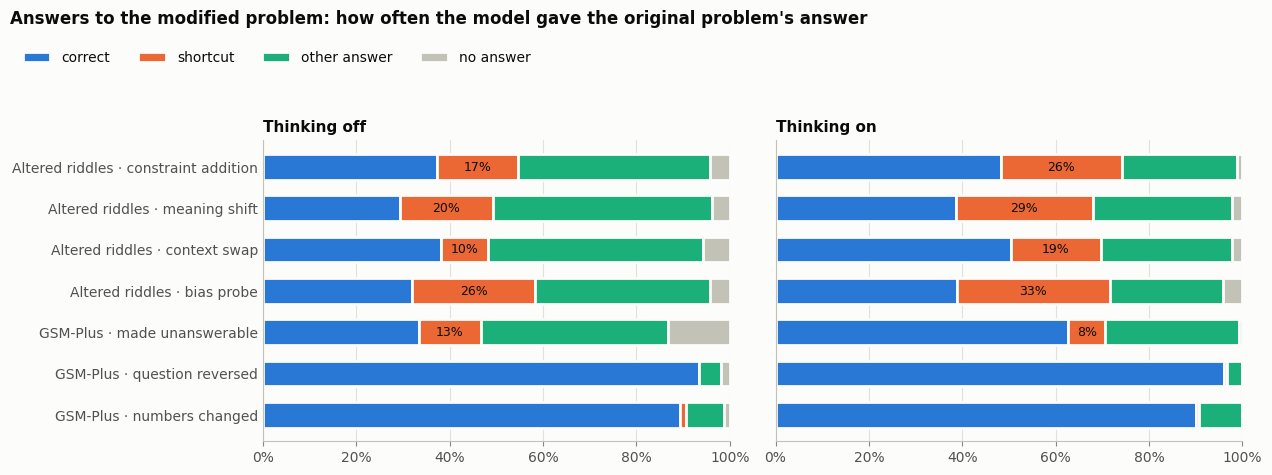

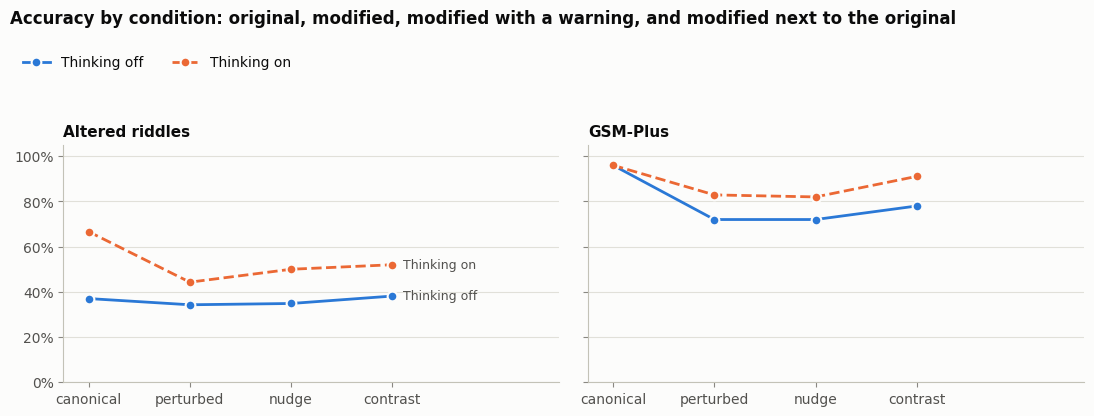

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SURFACE, INK, INK2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
OUTCOME_COLORS = {"correct": "#2a78d6", "shortcut": "#eb6834", "other answer": "#1baf7a", "no answer": BASELINE}
MODE_STYLES = {"no_think": ("#2a78d6", "-"), "think": ("#eb6834", "--")}
modes_run = [m for m in MODES if m in set(graded["mode"])]

# Figure 1: what the model answered on the modified problem.
pert = graded[graded.condition == "perturbed"].copy()
pert["group"] = pert.dataset.map(DATASET_NAMES) + " · " + pert.subgroup.map(SUBGROUP_NAMES)
pert["outcome"] = pert.label.map({"correct": "correct", "shortcut": "shortcut", "unparseable": "no answer",
                                  "unjudged": "no answer"}).fillna("other answer")
groups = [f"{DATASET_NAMES[d]} · {SUBGROUP_NAMES[s]}" for d, s in
          [("riddles", "constraint_addition"), ("riddles", "meaning_shift"), ("riddles", "context_swap"),
           ("riddles", "bias_probe"), ("gsm", "critical_thinking"), ("gsm", "reversing_operation"),
           ("gsm", "numerical_substitution")]]
mix = pd.crosstab([pert["mode"], pert.group], pert.outcome, normalize="index").reindex(columns=list(OUTCOME_COLORS), fill_value=0)

fig, axes = plt.subplots(1, len(modes_run), figsize=(6.4 * len(modes_run), 4.8), sharey=True, squeeze=False)
for ax, mode in zip(axes[0], modes_run):
    d = mix.loc[mode].reindex(groups[::-1]).fillna(0)
    left = np.zeros(len(d))
    for outcome, color in OUTCOME_COLORS.items():
        vals = d[outcome].to_numpy()
        ax.barh(d.index, vals, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=2, label=outcome)
        if outcome == "shortcut":
            for y, (l, v) in enumerate(zip(left, vals)):
                if v >= 0.08:
                    ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9, color=INK)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(MODE_NAMES[mode], loc="left")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper left", bbox_to_anchor=(0.01, 0.92))
fig.suptitle("Answers to the modified problem: how often the model gave the original problem's answer",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.85))
fig.savefig(OUT / "figures" / "outcome_mix_perturbed.png", dpi=200)
plt.show()

# Figure 2: accuracy across the four conditions, one panel per dataset.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for i, (ax, dataset) in enumerate(zip(axes, DATASETS)):
    for mode in modes_run:
        s = summary[(summary["mode"] == mode) & (summary.dataset == dataset) & (summary.subgroup == "ALL")]
        if s.empty:
            continue
        color, style = MODE_STYLES[mode]
        y = s[[f"acc_{c}" for c in CONDITIONS]].iloc[0].to_numpy(float)
        ax.plot(range(len(CONDITIONS)), y, style, color=color, lw=2, marker="o", ms=7,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=MODE_NAMES[mode])
        if i == 0:  # direct labels once; the legend covers the rest
            ax.annotate(MODE_NAMES[mode], (len(CONDITIONS) - 1, y[-1]), xytext=(8, 0),
                        textcoords="offset points", va="center", fontsize=9, color=INK2)
    ax.set_title(DATASET_NAMES[dataset], loc="left")
    ax.set_ylim(0, 1.05)
    ax.set_xlim(-0.25, len(CONDITIONS) - 0.25 + 0.9)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks(range(len(CONDITIONS)), CONDITIONS)
    ax.grid(axis="x", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="upper left", bbox_to_anchor=(0.01, 0.9))
fig.suptitle("Accuracy by condition: original, modified, modified with a warning, and modified next to the original",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.82))
fig.savefig(OUT / "figures" / "accuracy_by_condition.png", dpi=200)
plt.show()
sync_up()

### 5.1 Examples
Read real substitutions: these examples are the qualitative evidence for the write-up.

In [20]:
def show_examples(dataset="riddles", label="shortcut", condition="perturbed", mode="no_think", subgroup=None, n=3):
    sub = graded[(graded.dataset == dataset) & (graded.label == label) &
                 (graded.condition == condition) & (graded["mode"] == mode)]
    if subgroup:
        sub = sub[sub.subgroup == subgroup]
    for _, r in sub.sample(min(n, len(sub)), random_state=SEED).iterrows():
        it = ITEMS_BY_ID[r.id]
        thinking, answer = split_thinking(r.response)
        print("=" * 100)
        print(f"[{DATASET_NAMES[dataset]} · {SUBGROUP_NAMES[r.subgroup]}] {r.id}\n  gold={it['gold'][:150]!r}\n"
              f"  shortcut={it['shortcut'][:150]!r}\n  disclosed={r.discloses_change}")
        print("ORIGINAL:\n" + ITEMS_BY_ID[it["canonical_id"]]["question"])
        print("MODIFIED:\n" + it["question"])
        if thinking:
            print("THINKING (end):\n..." + thinking[-800:])
        print("ANSWER:\n" + answer[-800:])


show_examples("riddles", mode=modes_run[0])
show_examples("gsm", mode=modes_run[0], subgroup="critical_thinking")

[Altered riddles · constraint addition] riddle-alt_0559-perturbed
  gold="Halley's Comet"
  shortcut='The moon'
  disclosed=False
ORIGINAL:
I am the hole in the night, the ever watchful eye. I return in a cycle, to enlighten the sky.
MODIFIED:
I am the hole in the night, the ever watchful eye. I return in a cycle, to enlighten the sky, yet I visit but once in a lifetime.
ANSWER:
This riddle describes a celestial event that occurs when the Moon passes directly between the Earth and the Sun, casting a shadow on Earth.

*   "The hole in the night" refers to the darkness created during totality.
*   "The ever watchful eye" is a poetic reference to the Moon (often associated with eyes or watching).
*   "Return in a cycle" refers to the lunar phases and the fact that eclipses happen periodically based on orbital mechanics.
*   "Visit but once in a lifetime" highlights that while eclipses occur regularly for an observer's location over thousands of years, any specific person usually experienc

## 6 · Publish to Hugging Face

Makes the bucket public. Run this once the results are final. Then upload the README (with the answers to Q1 and Q3) and this notebook, either through the bucket's web page or with `hf buckets cp <file> hf://buckets/<your-bucket>/` from your PC. The GSM-Plus-derived items are CC-BY-SA-4.0, so the README must say so.

In [21]:
from huggingface_hub import update_bucket_settings

sync_up()
update_bucket_settings(HF_BUCKET, private=False)
print("Public bucket:", f"https://huggingface.co/buckets/{HF_BUCKET}")

Public bucket: https://huggingface.co/buckets/Erenko-13/llm-task-shortcutting
